# 00 - Choosing the radii

The clustering starts the clock when a particle first crosses **2.5N** and
describes it by **where it first gets farther than R km from its own crossing
point** (haversine distance), for every R in `config.RADII_KM`. This notebook
shows why those radii were chosen.

It reads a sample of stores (every `STORE_STEP`-th store of each track dir) and
uses the same functions as Stage 1 (`P.first_crossing`,
`P.distance_from_crossing`, `P.first_exit`). Nothing is written to `data/`; the
two figures are saved in `figures/`.

**One particle, step by step:** it crosses 2.5N at 47W. Draw circles of 200,
500, 1000, ... km around that point. Its features are the positions where its
track first leaves each circle. A fast and a slow particle that follow the same
route get the same features - time is not part of the clustering (it is kept
in `days_<R>km` for the diagnostics).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [200, 500, 1000, 1500, 2000, 3000, 4000]


In [2]:
STORE_STEP = 60          # every 60th store of each track dir (~28 stores, ~280k particles)
N_SHOW     = 300         # random trajectories drawn on the map

In [3]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs, cartopy.feature as cfeature
from joblib import Parallel, delayed

# --- TUNE ME (also STORE_STEP / N_SHOW above) --------------------------------
CAND_R     = np.union1d(np.arange(100, 4001, 100), C.RADII_KM)   # radii for the curves
N_JOBS     = int(os.environ.get("SLURM_CPUS_PER_TASK", 8))
# -----------------------------------------------------------------------------

stores = []
for d in C.TRACK_DIRS:
    stores += sorted((C.DATA_ROOT / d).glob(C.STORE_GLOB))[::STORE_STEP]
print(len(stores), "stores in the sample")

28 stores in the sample


## Per-store numbers

For every crossing particle and every candidate radius: the days after the
crossing at which it first gets that far (NaN = never, its track ended first),
and for the chosen radii the compass direction (bearing) from the crossing
point to the exit point. A few whole tracks per store are kept for the map.

In [4]:
CHOSEN = [int(np.where(CAND_R == r)[0][0]) for r in C.RADII_KM]
n_show_store = int(np.ceil(N_SHOW / len(stores)))

def store_stats(path, seed):
    ds = xr.open_zarr(path)
    lat = ds.lat.values.astype(np.float64)
    lon = ds.lon.values.astype(np.float64)
    time = ds.time.values
    rows = np.arange(lat.shape[0])

    k0, crossed = P.first_crossing(lat)
    dist = P.distance_from_crossing(lat, lon, k0, crossed)
    idx, reached = P.first_exit(dist, CAND_R)
    t_rel = (time - time[rows, k0][:, None]) / np.timedelta64(1, "D")   # days since crossing
    days = np.where(reached, t_rel[rows[:, None], idx], np.nan)

    la0, lo0 = lat[rows, k0], lon[rows, k0]
    ci = idx[:, CHOSEN]
    bear = P.bearing_deg(la0[:, None], lo0[:, None],
                         lat[rows[:, None], ci], lon[rows[:, None], ci])
    bear[~reached[:, CHOSEN]] = np.nan

    rng = np.random.default_rng(seed)
    show = rng.choice(np.where(crossed)[0], n_show_store, replace=False)
    return dict(n=lat.shape[0], days=days[crossed], bear=bear[crossed],
                rmax=np.nanmax(dist[crossed], axis=1),
                show_lat=lat[show], show_lon=lon[show], show_k0=k0[show])

res = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(store_stats)(p, i) for i, p in enumerate(stores))

n_all  = sum(r["n"] for r in res)
days   = np.concatenate([r["days"] for r in res])     # (crossers, len(CAND_R))
bear   = np.concatenate([r["bear"] for r in res])     # (crossers, len(RADII_KM))
rmax   = np.concatenate([r["rmax"] for r in res])
n_obs  = max(r["show_lat"].shape[1] for r in res)      # stores hold 740 or 741 outputs
def _pad(a):
    return np.pad(a, ((0, 0), (0, n_obs - a.shape[1])), constant_values=np.nan)
s_lat  = np.concatenate([_pad(r["show_lat"]) for r in res])[:N_SHOW]
s_lon  = np.concatenate([_pad(r["show_lon"]) for r in res])[:N_SHOW]
s_k0   = np.concatenate([r["show_k0"] for r in res])[:N_SHOW]
print(f"{n_all:,} particles, {len(days):,} cross {C.LAT_CROSS}N ({100*len(days)/n_all:.1f}%)")

frac = 100 * (~np.isnan(days)).mean(axis=0)            # % of crossers reaching R
med  = np.nanmedian(days, axis=0)
p10, p90 = np.nanpercentile(days, [10, 90], axis=0)

tab = pd.DataFrame({"reached [%]": frac[CHOSEN],
                    "median days after crossing": med[CHOSEN],
                    "p10": p10[CHOSEN], "p90": p90[CHOSEN]},
                   index=pd.Index(C.RADII_KM, name="radius [km]")).round(1)
print(tab.to_string())
print(f"\nfarthest distance from the crossing point: median {np.median(rmax):.0f} km, "
      f"5-95%: {np.percentile(rmax, 5):.0f}-{np.percentile(rmax, 95):.0f} km")

282,648 particles, 275,714 cross 2.5N (97.5%)
             reached [%]  median days after crossing    p10    p90
radius [km]                                                       
200                 99.6                         9.0    4.2   17.0
500                 99.1                        14.5    7.8   32.0
1000                97.5                        31.8   17.2   67.8
1500                89.7                        51.0   29.8  106.2
2000                73.9                        72.8   46.0  128.8
3000                23.0                       119.0   83.8  154.5
4000                 2.0                       140.8  104.8  164.0

farthest distance from the crossing point: median 2468 km, 5-95%: 1231-3613 km


## Figure 1 - the circles on a map

**Left:** `N_SHOW` random particles from their crossing onwards, with the
circles drawn around the median crossing point and each particle's exit points
coloured by radius. (In the features every particle uses circles around its
*own* crossing point; one set is drawn here to keep the map readable.)
**Right:** one particle with its own circles; the dashed grey part is before
the crossing, which the clustering ignores.

/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/shapely/creation.py:218: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/shapely/creation.py:218: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/shapely/creation.py:218: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/shapely/creation.py:218: RuntimeWarning: invalid value encountered in linestrings
  return lib.linestrings(coords, np.intc(handle_nan), out=out, **kwargs)
/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/shape

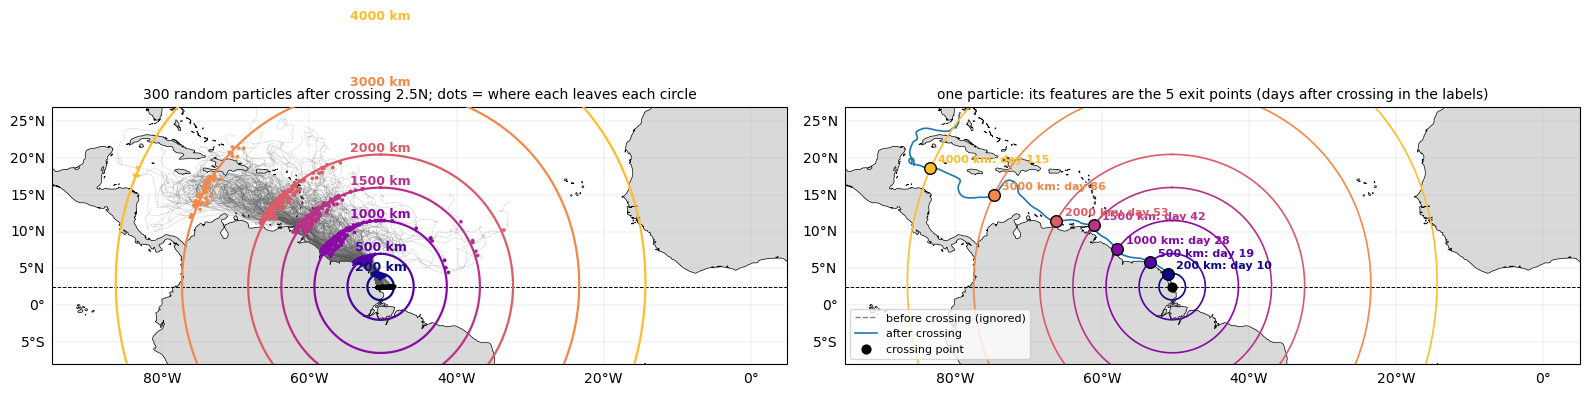

In [5]:
pc = ccrs.PlateCarree()
rcol = plt.get_cmap("plasma", len(C.RADII_KM) + 1)
rcolor = {r: rcol(i) for i, r in enumerate(C.RADII_KM)}
ext = [C.DOMAIN["lon_min"], C.DOMAIN["lon_max"], C.DOMAIN["lat_min"], C.DOMAIN["lat_max"]]

def show_exits(la, lo, k0):
    crossed = np.ones(len(k0), bool)
    d = P.distance_from_crossing(la, lo, k0, crossed)
    idx, reached = P.first_exit(d, C.RADII_KM)
    return idx, reached

idx_s, reach_s = show_exits(s_lat, s_lon, s_k0)
lat_c, lon_c = C.LAT_CROSS, float(np.median(s_lon[np.arange(len(s_k0)), s_k0]))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), subplot_kw={"projection": pc})
for ax in axes:
    ax.set_extent(ext, crs=pc)
    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=0); ax.coastlines(lw=.5)
    gl = ax.gridlines(draw_labels=True, lw=.3, color="0.7", alpha=.5)
    gl.top_labels = gl.right_labels = False
    ax.axhline(C.LAT_CROSS, color="k", lw=.7, ls="--")

# (a) many particles, circles around the median crossing point
ax = axes[0]
for i in range(len(s_k0)):
    ax.plot(s_lon[i, s_k0[i]:], s_lat[i, s_k0[i]:], "-", color="0.35", lw=.3,
            alpha=.35, transform=pc)
ax.scatter(s_lon[np.arange(len(s_k0)), s_k0], s_lat[np.arange(len(s_k0)), s_k0],
           s=4, color="k", zorder=4, transform=pc, label="crossing point")
for j, r in enumerate(C.RADII_KM):
    cla, clo = P.circle_latlon(lat_c, lon_c, r)
    ax.plot(clo, cla, "-", color=rcolor[r], lw=1.6, transform=pc, zorder=3)
    ax.text(clo[0], cla[0] + .4, f"{r} km", color=rcolor[r], fontsize=9,
            ha="center", fontweight="bold", transform=pc, zorder=5)
    ok = reach_s[:, j]
    ii = np.where(ok)[0]
    ax.scatter(s_lon[ii, idx_s[ii, j]], s_lat[ii, idx_s[ii, j]], s=7,
               color=rcolor[r], edgecolor="none", zorder=4, transform=pc)
ax.set_title(f"{len(s_k0)} random particles after crossing {C.LAT_CROSS}N; "
             f"dots = where each leaves each circle", fontsize=10)

# (b) one particle with its own circles
ax = axes[1]
rng = np.random.default_rng(C.RANDOM_STATE)
i = int(rng.choice(np.where(reach_s.all(axis=1))[0]))
k0 = s_k0[i]
ax.plot(s_lon[i, :k0 + 1], s_lat[i, :k0 + 1], "--", color="0.5", lw=1, transform=pc,
        label="before crossing (ignored)")
ax.plot(s_lon[i, k0:], s_lat[i, k0:], "-", color="tab:blue", lw=1.2, transform=pc,
        label="after crossing")
ax.scatter(s_lon[i, k0], s_lat[i, k0], s=40, color="k", zorder=5, transform=pc,
           label="crossing point")
for j, r in enumerate(C.RADII_KM):
    cla, clo = P.circle_latlon(s_lat[i, k0], s_lon[i, k0], r)
    ax.plot(clo, cla, "-", color=rcolor[r], lw=1.2, transform=pc)
    k = idx_s[i, j]
    ax.scatter(s_lon[i, k], s_lat[i, k], s=70, color=rcolor[r], edgecolor="k",
               zorder=6, transform=pc)
    ax.annotate(f"{r} km: day {(k - k0) / 4:.0f}", (s_lon[i, k], s_lat[i, k]),
                xytext=(6, 4), textcoords="offset points", fontsize=8,
                color=rcolor[r], fontweight="bold")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("one particle: its features are the 5 exit points "
             "(days after crossing in the labels)", fontsize=10)
fig.tight_layout()
fig.savefig(C.FIG_DIR / "00_radius_choice_map.png", dpi=140, bbox_inches="tight")
plt.show()

## Figure 2 - how far particles get, how long it takes, and how the exit directions spread

* **Left:** share of crossing particles that ever get R km away. Every run_2
  track stops 185 days after release, and particles cross 2.5N at different
  times, so the larger the radius, the more tracks end first. A particle that
  does not reach a radius gets its last position instead (`partial`) - the
  more of those, the less that radius means.
* **Middle:** days after the crossing to get there (median, 10-90% band).
* **Right:** direction from the crossing point to the exit point at each chosen
  radius (0 = N, -90 = W, 90 = E). A radius where everyone exits in the same
  direction cannot separate pathways; a spread or several peaks can.

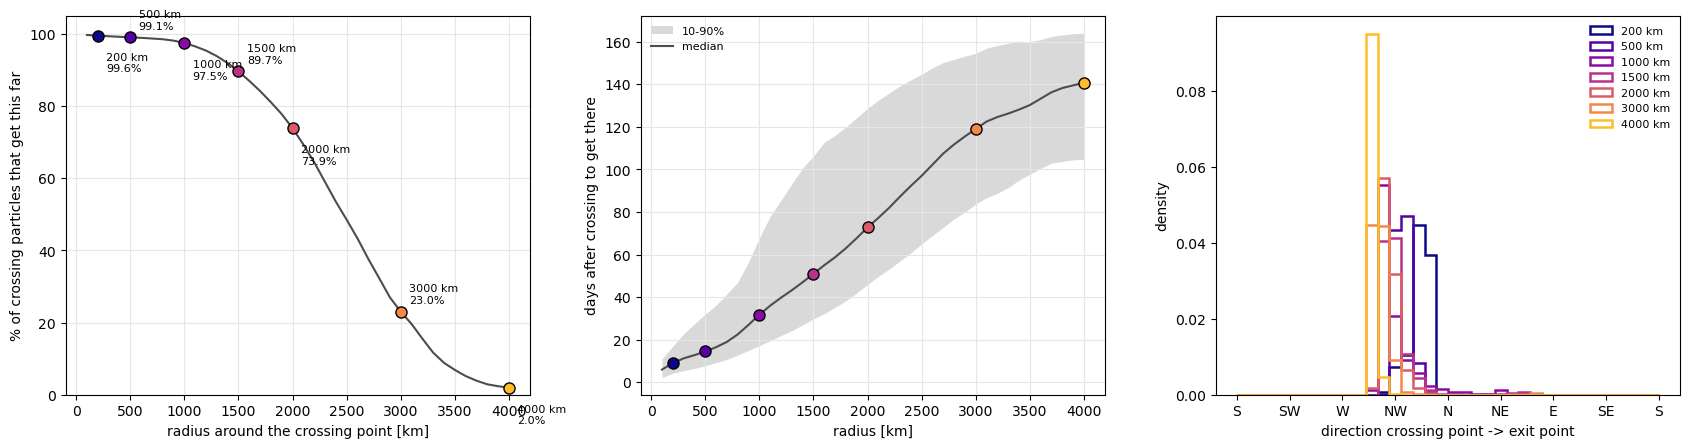

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

ax[0].plot(CAND_R, frac, "-", color="0.3")
for n, (j, r) in enumerate(zip(CHOSEN, C.RADII_KM)):
    ax[0].plot(r, frac[j], "o", color=rcolor[r], ms=8, mec="k")
    ax[0].annotate(f"{r} km\n{frac[j]:.1f}%", (r, frac[j]),
                   xytext=(6, 6) if n % 2 else (6, -26),       # alternate so labels don't overlap
                   textcoords="offset points", fontsize=8)
ax[0].set_xlabel("radius around the crossing point [km]")
ax[0].set_ylabel("% of crossing particles that get this far")
ax[0].set_ylim(0, 105); ax[0].grid(color="0.9")

ax[1].fill_between(CAND_R, p10, p90, color="0.85", lw=0, label="10-90%")
ax[1].plot(CAND_R, med, "-", color="0.3", label="median")
for j, r in zip(CHOSEN, C.RADII_KM):
    ax[1].plot(r, med[j], "o", color=rcolor[r], ms=8, mec="k")
ax[1].set_xlabel("radius [km]"); ax[1].set_ylabel("days after crossing to get there")
ax[1].legend(fontsize=8, frameon=False); ax[1].grid(color="0.9")

bins = np.arange(-180, 181, 10)
for j, r in enumerate(C.RADII_KM):
    b = bear[:, j][~np.isnan(bear[:, j])]
    ax[2].hist(b, bins=bins, histtype="step", lw=1.8, color=rcolor[r],
               density=True, label=f"{r} km")
ax[2].set_xticks([-180, -135, -90, -45, 0, 45, 90, 135, 180])
ax[2].set_xticklabels(["S", "SW", "W", "NW", "N", "NE", "E", "SE", "S"])
ax[2].set_xlabel("direction crossing point -> exit point")
ax[2].set_ylabel("density"); ax[2].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(C.FIG_DIR / "00_radius_choice_stats.png", dpi=140, bbox_inches="tight")
plt.show()

## Why 200 / 500 / 1000 / 1500 / 2000 km

From the first look at a 28-store sample (2026-10-08); the cells above
recompute these numbers each run:

| radius | reached | median days after crossing | role |
|---|---|---|---|
| 200 km | 99.6% | 9 | gate: almost everyone, still near the NBC |
| 500 km | 99.1% | 15 | early direction (along the shelf vs offshore) |
| 1000 km | 97.5% | 32 | retroflection vs continuing northwest |
| 1500 km | 89.7% | 51 | towards the Antilles vs eastward |
| 2000 km | 73.9% | 73 | destination: about the Lesser Antilles to the NW, ~30W along the retroflection to the E |
| 2500 km | 48.5% | 97 | not used: half the particles would have a filled-in last position |

* **Not every 100 km:** every radius gets the same weight after
  standardization, so many closely spaced small radii would let the near field
  (where pathways have not separated yet) dominate. Check the bearing panel:
  the small radii should be the narrowest.
* **Stop at 2000 km:** beyond it too many tracks end before getting there
  (left panel), and the stand-in last position would be taken at a different
  stage of the journey for each particle.
* **Weights** (`config.RADIUS_WEIGHTS`) start at 1 for every radius and are
  tuned by eye in notebook 1.5, as with the days.
* Particles move away steadily: the farthest distance is close to the distance
  at the end of the track, so "first time past R" is rarely followed by a
  return inside the circle.